In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

In [5]:
df = pd.read_csv('kmeans_project/kmeans_dataset.csv')
df.head()


FileNotFoundError: [Errno 2] No such file or directory: 'kmeans_project\\kmeans_dataset.csv'

In [ ]:
df = df.apply(pd.to_numeric, errors='coerce')
df = df.dropna(subset=['Age', 'Annual_Income_USD', 'Spending_Score', 'Purchase_Frequency_PerYear', 'Avg_Cart_Value_USD'])
df = df.reset_index(drop=True)

In [6]:
features = [
    'Age',
    'Annual_Income_USD',
    'Spending_Score',
    'Purchase_Frequency_PerYear',
    'Avg_Cart_Value_USD'
]

In [7]:
x = df[features]
x_scaled = StandardScaler().fit_transform(x)
x_scaled

NameError: name 'df' is not defined

In [8]:
inertias = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=12,
        random_state=42
    )
    kmeans.fit(x_scaled)
    inertias.append(kmeans.inertia_)

plt.plot(range(2, 11), inertias, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.show()

NameError: name 'x_scaled' is not defined

In [9]:
clus_num = 4
k_means = KMeans(init = 'k-means++', n_clusters = clus_num, n_init=12, random_state=42)
k_means.fit(x_scaled)
labels = k_means.labels_
labels

NameError: name 'x_scaled' is not defined

In [ ]:
df["Clus_km"] = labels
df.head(5)

In [10]:
df.groupby('Clus_km')[features].mean()

NameError: name 'df' is not defined

In [ ]:
area = x['Annual_Income_USD'] / x['Annual_Income_USD'].max() * 200
plt.scatter(
    x['Age'],
    x['Annual_Income_USD'],
    s=area,
    c=labels.astype(float),
    alpha=0.7
)
plt.xlabel('Age', fontsize=16)
plt.ylabel('Annual Income USD', fontsize=16)
plt.show()

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(x_scaled)

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels,
    alpha=0.7
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('K-Means Clusters using PCA')
plt.show()

NameError: name 'x' is not defined

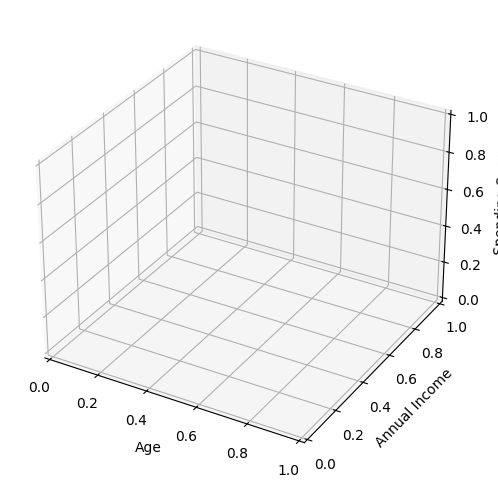

In [11]:
fig = plt.figure(figsize=(8, 6))

ax = fig.add_subplot(
    111,
    projection='3d'
)

ax.set_xlabel('Age')
ax.set_ylabel('Annual Income')
ax.set_zlabel('Spending Score')

ax.scatter(
    x['Age'],
    x['Annual_Income_USD'],
    x['Spending_Score'],
    c=labels,
    alpha=0.7
)

plt.show()